<a href="https://colab.research.google.com/github/chandra-prakash-khudia/micrograd/blob/main/micrograd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [156]:
class Value:
  def __init__(self,data, _children=(), _ops='', label=''):
    self.data = data
    self._prev = set(_children)
    self._ops = _ops
    self.label = label
    self._backward = lambda: None
    self.grad = 0.0
  def __repr__(self):
    return f"Value (data ={self.data})"
  def __add__(self,other):
    other = other if isinstance(other, Value) else Value(other)
    out= Value(self.data + other.data, (self,other) , '+')
    def _backward():
      self.grad +=1.0 * out.grad
      other.grad += 1.0 *out.grad
    out._backward = _backward
    return out
  def __mul__(self,other):
    other = other if isinstance(other, Value) else Value(other)
    out =  Value(self.data * other.data , (self,other) , '*')
    def _backward():
      self.grad  += other.data * out.grad
      other.grad  += self.data * out.grad
    out._backward = _backward
    return out
  def __rmul__(self,other):
    return self * other
  def __truediv__(self,other):
    return self * other**-1
  def __neg__(self):
    return self * -1
  def __sub__(self,other):
    return self + (-other)
  def __radd__(self,other):
    return self + other
  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self,), 'tanh')
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    return out
  def __pow__(self,other):
    assert isinstance(other, (int,float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')
    def _backward():
      self.grad += other * self.data**(other-1) * out.grad
    out._backward = _backward
    return out
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self,), 'exp')
    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward
    return out

  def backward(self):

    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [129]:
from graphviz import Digraph

def trace(root):
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child,v))
        build(child)
  build(root)
  return nodes, edges
def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label,n.data, n.grad), shape='record')
    if n._ops:
      dot.node(name = uid + n._ops, label = n._ops)
      dot.edge(uid + n._ops, uid)
      # for child in n._prev:
      # dot.edge(str(id(child)), str(id(n)))
  for n1, n2 in edges:
    dot.edge(str(id(n1)), str(id(n2)) + n2._ops)
  return dot

In [142]:
# Re-build the network utilizing the corrected class blueprint
x1 = Value(2.0, label='x1')
x2 = Value(1.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

# Initialize the top-level output gradient


In [148]:
o.backward()

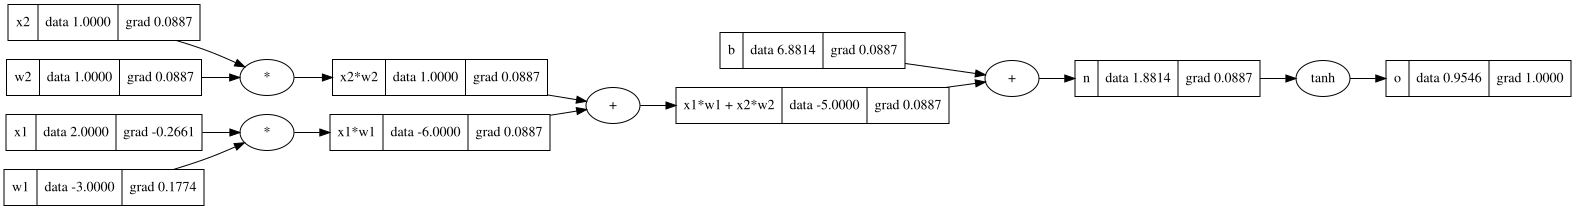

In [149]:
# Draw the updated computational graph with the new gradient values
draw_dot(o)

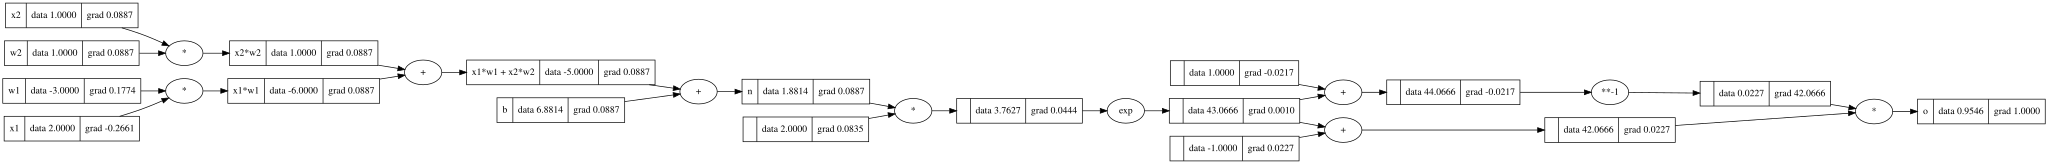

In [157]:
x1 = Value(2.0, label='x1')
x2 = Value(1.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
e = (2*n).exp()
o = (e-1)/(e +1)
o.label = 'o'
o.backward()
draw_dot(o)